# Especialización funcional entre cabezas de un bloque — vectores de daño por clase (2026-08-30)

Bloque B del capítulo (*circuit study*), extensión de `notebooks/22082026_ablation/ablation.ipynb`.
La ablación de ese notebook mide *cuánto* cae la accuracy global al apagar cada cabeza. Acá se mira
*a qué clases* le pega cada cabeza: se ablaciona una cabeza a la vez, se calcula la caída de accuracy
**por clase** (vector de dim 10), y se comparan esos "vectores de daño" entre cabezas del mismo bloque.

- Si dos cabezas tienen vectores de daño muy **parecidos** (coseno / Pearson altos) -> hacen un trabajo
  redundante: apagar una o la otra rompe las mismas clases.
- Si son **distintos / ortogonales** -> están especializadas en clases diferentes.

La hipótesis del capítulo es que el modelo penalizado ("interpretable") tiene cabezas con vectores de
daño **menos correlacionados** que el baseline (menos información compartida entre cabezas).

**Ambos modelos en una corrida.** La celda de configuración elige `BLOCK_IDX` y carga
`MODELS = {"baseline": ..., "interpretable": ...}`; cada tarea calcula y grafica para los dos, y cada
imagen se guarda con el nombre del modelo (y el bloque) en el archivo, sin pisarse entre sí. El nombre
exacto con el que se guardó cada imagen se imprime debajo de la gráfica.

Sample de referencia: las primeras `N_REF=1000` imágenes del test de AwA2, con sus labels.

## 0. Configuración — carga ambos modelos

In [1]:
# ======================================================================
#  CONFIGURACIÓN
# ======================================================================
BLOCK_IDX = 4   # bloque a analizar, 1-indexed. Internamente se pasa a 0-indexed.
N_REF     = 1000
# ======================================================================

import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

# Misma convención que el resto de notebooks/: vive 2 niveles bajo la raíz del proyecto.
project_root = Path.cwd().resolve().parents[1]
sys.path.append(str(project_root))

from modules.model import ViTForClassfication
from modules.datasets import AwA2Dataset
from modules.figures import save_fig

torch.manual_seed(0)

EXPERIMENTS_DIR = project_root / "experimentation" / "experiments"
OUTPUT_DIR = EXPERIMENTS_DIR / "30082026_head_specialization"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODELS = {
    "unconstrained": "vit-15-AwA2",
    "constrained": "vit-15-constrained-AwA2",
    "constrained_rank": "vit-15-constrained_rank-AwA2"
}

print(f"BLOCK_IDX  : {BLOCK_IDX}  (1-indexed)")
print(f"OUTPUT_DIR : {OUTPUT_DIR.relative_to(project_root)}")
print(f"N_REF      : {N_REF}")

BLOCK_IDX  : 4  (1-indexed)
OUTPUT_DIR : experimentation/experiments/30082026_head_specialization
N_REF      : 1000


## 1. Cargar los dos modelos

El `assert` sobre `use_faster_attention` protege la ablación por cabeza (asume `block.attention.heads`
como submódulos separados). Se convierte `BLOCK_IDX` (1-indexed) al índice 0-indexed `block_idx0` que
usan las funciones de ablación.

In [2]:
def load_model(name):
    exp_dir = EXPERIMENTS_DIR / name
    with open(exp_dir / "config.json") as f:
        config = json.load(f)
    with open(exp_dir / "metrics.json") as f:
        metrics = json.load(f)
    assert not config["use_faster_attention"], (
        "Este notebook asume block.attention.heads (cabezas separadas); "
        "con use_faster_attention=True habría que adaptar la ablación por cabeza."
    )
    model = ViTForClassfication(config)
    model.load_state_dict(torch.load(exp_dir / "model_final.pt", map_location="cpu"))
    model.eval()
    return model, config, metrics


models = {key: load_model(name) for key, name in MODELS.items()}

config = models["unconstrained"][1]
assert all(m[1] == config for m in models.values()), "Los modelos deben tener la misma arquitectura"

n_blocks    = len(models["unconstrained"][0].encoder.blocks)
n_heads     = config["num_attention_heads"]
num_classes = config["num_classes"]

assert 1 <= BLOCK_IDX <= n_blocks, f"BLOCK_IDX debe estar en 1..{n_blocks} (1-indexed); recibí {BLOCK_IDX}"
block_idx0 = BLOCK_IDX - 1
head_labels = [f"head {h + 1}" for h in range(n_heads)]

for key, (_, _, metrics) in models.items():
    print(f"{key:>13} ({MODELS[key]}): accuracy de entrenamiento = {metrics['accuracy']:.4f}")
print(f"bloques={n_blocks} | cabezas/bloque={n_heads} | clases={num_classes}")
print(f"Bloque a analizar: block {BLOCK_IDX}  (índice interno {block_idx0})  ->  {n_heads} cabezas")

unconstrained (vit-15-AwA2): accuracy de entrenamiento = 0.2971
  constrained (vit-15-constrained-AwA2): accuracy de entrenamiento = 0.2879
constrained_rank (vit-15-constrained_rank-AwA2): accuracy de entrenamiento = 0.2973
bloques=4 | cabezas/bloque=4 | clases=50
Bloque a analizar: block 4  (índice interno 3)  ->  4 cabezas


## 2. Sample de referencia (n = 1000, con labels)

Primeras `N_REF` imágenes del test de AwA2 y sus labels de clase. `AwA2Dataset` usa el cache local ya
construido en `data/awa2/`, así que no vuelve a descargar nada.

In [3]:
dataset = AwA2Dataset(image_size=32, root=str(project_root / "data" / "awa2"))
_, testloader, classes_tuple = dataset.get_loaders(batch_size=256)
classes = list(classes_tuple)

# Todo el test (el testset de AwA2 viene ordenado por clase: las primeras N imágenes cubren solo ~9 de 50 clases)
N_REF = len(dataset.testset)
ref_images, ref_labels = dataset.get_samples_from_indices(range(len(dataset.testset)), device="cpu", set="test")
_counts = torch.bincount(ref_labels, minlength=num_classes).tolist()
print(f"Sample de referencia: {tuple(ref_images.shape)}  (índices 0..{N_REF - 1} del test)")
print("imágenes por clase:", {c: n for c, n in zip(classes, _counts)})
assert any(n > 0 for n in _counts), "Ninguna clase aparece en el sample; subir N_REF."

Sample de referencia: (7468, 3, 32, 32)  (índices 0..7467 del test)
imágenes por clase: {'antelope': 209, 'grizzly bear': 170, 'killer whale': 58, 'beaver': 39, 'dalmatian': 110, 'persian cat': 149, 'horse': 329, 'german shepherd': 207, 'blue whale': 35, 'siamese cat': 100, 'skunk': 38, 'mole': 20, 'tiger': 175, 'hippopotamus': 137, 'leopard': 144, 'moose': 141, 'spider monkey': 58, 'humpback whale': 142, 'elephant': 208, 'gorilla': 174, 'ox': 146, 'fox': 133, 'sheep': 284, 'seal': 198, 'chimpanzee': 146, 'hamster': 156, 'squirrel': 240, 'rhinoceros': 139, 'rabbit': 218, 'bat': 77, 'giraffe': 240, 'wolf': 118, 'chihuahua': 113, 'rat': 62, 'weasel': 54, 'otter': 152, 'buffalo': 179, 'zebra': 234, 'giant panda': 175, 'deer': 269, 'bobcat': 126, 'pig': 143, 'lion': 204, 'mouse': 37, 'polar bear': 174, 'collie': 206, 'walrus': 43, 'raccoon': 102, 'cow': 268, 'dolphin': 189}


## 3. Funciones: ablación por cabeza + accuracy por clase

`forward_with_head_ablated` es **la misma función de `notebooks/22082026_ablation/ablation.ipynb`**
(copiada tal cual): reconstruye la atención del bloque `ablate_layer_idx` a mano, corre cada cabeza por
separado y pone en **cero** la salida de `ablate_head_idx` antes de concatenar y proyectar; el resto del
modelo queda intacto. Con `ablate_layer_idx=None` no toca nada (se usa para el sanity check).

`per_class_accuracy` desglosa la accuracy en los 10 valores por clase.

In [4]:
@torch.no_grad()
def forward_with_head_ablated(model, x, ablate_layer_idx=None, ablate_head_idx=None):
    h = model.embedding(x)
    for i, block in enumerate(model.encoder.blocks):
        if i == ablate_layer_idx:
            attn_in = block.layernorm_1(h)
            head_outputs = []
            for hidx, head in enumerate(block.attention.heads):
                out, _ = head(attn_in)
                if hidx == ablate_head_idx:
                    out = torch.zeros_like(out)   # <- ablación: salida de esa cabeza a cero
                head_outputs.append(out)
            concat = torch.cat(head_outputs, dim=-1)
            attn_out = block.attention.output_projection(concat)
            attn_out = block.attention.output_dropout(attn_out)
            h = h + attn_out
            mlp_out = block.mlp(block.layernorm_2(h))
            h = h + mlp_out
        else:
            h, _ = block(h, output_attentions=False)
    return model.classifier(h[:, 0, :])


@torch.no_grad()
def accuracy_of(logits, labels):
    return (logits.argmax(dim=-1) == labels).float().mean().item()


@torch.no_grad()
def per_class_accuracy(logits, labels, num_classes):
    """Vector de dim num_classes: accuracy dentro de cada clase (correctos_c / total_c)."""
    preds = logits.argmax(dim=-1)
    accs = np.full(num_classes, np.nan)
    for c in range(num_classes):
        mask = labels == c
        n_c = int(mask.sum())
        if n_c > 0:
            accs[c] = (preds[mask] == labels[mask]).float().mean().item()
    return accs


# Sanity check: sin ablación, la reimplementación manual debe coincidir EXACTO con el forward
# normal, para cada modelo. También queda cacheado direct_logits por modelo, reutilizado abajo.
direct_logits = {}
for key, (model, _, _) in models.items():
    with torch.no_grad():
        direct_logits[key], _ = model(ref_images, output_attentions=False)
    head_fn_logits = forward_with_head_ablated(model, ref_images, ablate_layer_idx=None, ablate_head_idx=None)
    _diff = (direct_logits[key] - head_fn_logits).abs().max().item()
    assert _diff < 1e-5, f"{key}: sin ablación la función debe reproducir el forward normal"
    print(f"[{key}] diferencia máxima (forward_with_head_ablated, sin ablar) vs forward normal: {_diff:.2e}")
print("OK - la reimplementación manual es fiel al forward original, en ambos modelos.")

[unconstrained] diferencia máxima (forward_with_head_ablated, sin ablar) vs forward normal: 0.00e+00


[constrained] diferencia máxima (forward_with_head_ablated, sin ablar) vs forward normal: 0.00e+00


[constrained_rank] diferencia máxima (forward_with_head_ablated, sin ablar) vs forward normal: 0.00e+00
OK - la reimplementación manual es fiel al forward original, en ambos modelos.


## Tarea 1 — Accuracy baseline por clase (sin ablación)

Forward pass completo sobre el sample de referencia, sin tocar nada. Se guarda el vector
`accuracy_baseline_per_class` (dim 10) que es la referencia contra la que se mide el daño de cada cabeza.

In [5]:
accuracy_baseline_global = {}
accuracy_baseline_per_class = {}
for key in MODELS:
    accuracy_baseline_global[key] = accuracy_of(direct_logits[key], ref_labels)
    accuracy_baseline_per_class[key] = per_class_accuracy(direct_logits[key], ref_labels, num_classes)

    print(f"[{key}] Accuracy global baseline (n={N_REF}): {accuracy_baseline_global[key]:.4f}")
    print(f"[{key}] Accuracy baseline por clase:")
    for c, name in enumerate(classes):
        print(f"  {name:>16}: {accuracy_baseline_per_class[key][c]:.4f}")
    print()

[unconstrained] Accuracy global baseline (n=7468): 0.2971
[unconstrained] Accuracy baseline por clase:
          antelope: 0.3445
      grizzly bear: 0.2176
      killer whale: 0.0345
            beaver: 0.0000
         dalmatian: 0.2636
       persian cat: 0.1678
             horse: 0.4529
   german shepherd: 0.0145
        blue whale: 0.0286
       siamese cat: 0.0200
             skunk: 0.2895
              mole: 0.0000
             tiger: 0.2743
      hippopotamus: 0.1241
           leopard: 0.3194
             moose: 0.0284
     spider monkey: 0.0345
    humpback whale: 0.6338
          elephant: 0.3990
           gorilla: 0.6552
                ox: 0.0274
               fox: 0.1203
             sheep: 0.5669
              seal: 0.4293
        chimpanzee: 0.1027
           hamster: 0.3269
          squirrel: 0.1083
        rhinoceros: 0.3022
            rabbit: 0.3853
               bat: 0.0260
           giraffe: 0.1375
              wolf: 0.0339
         chihuahua: 0.2212
      

## Tarea 2 — Vector de daño por clase, por cada cabeza del bloque

Para cada una de las `n_heads` cabezas de `block BLOCK_IDX`: se ablaciona **solo esa cabeza**, se corre
el forward sobre el mismo sample, se calcula la accuracy por clase, y

```
damage_vector[head] = accuracy_baseline_per_class - accuracy_ablated_per_class   # dim 10
```

Daño positivo = esa clase empeora al apagar la cabeza (la cabeza ayudaba a esa clase). Daño negativo =
la clase mejora al apagarla. Los `n_heads` vectores se apilan en `damage_matrix` de shape `(n_heads, 10)`.

In [6]:
damage_matrix = {}
for key, (model, _, _) in models.items():
    damage_matrix[key] = np.zeros((n_heads, num_classes))
    for hidx in range(n_heads):
        logits = forward_with_head_ablated(model, ref_images, ablate_layer_idx=block_idx0, ablate_head_idx=hidx)
        acc_c = per_class_accuracy(logits, ref_labels, num_classes)
        damage_matrix[key][hidx] = accuracy_baseline_per_class[key] - acc_c
        drop_global = accuracy_baseline_global[key] - accuracy_of(logits, ref_labels)
        print(f"[{key}] block {BLOCK_IDX}, head {hidx + 1}: caída global = {drop_global:+.4f}  |  "
              f"daño por clase [min {damage_matrix[key][hidx].min():+.3f}, max {damage_matrix[key][hidx].max():+.3f}]")

    print(f"\n[{key}] damage_matrix (filas = cabezas, columnas = clases):")
    print(pd.DataFrame(damage_matrix[key], index=head_labels, columns=classes).round(3))
    print()

[unconstrained] block 4, head 1: caída global = +0.0165  |  daño por clase [min -0.068, max +0.138]


[unconstrained] block 4, head 2: caída global = +0.0197  |  daño por clase [min -0.088, max +0.225]


[unconstrained] block 4, head 3: caída global = +0.0011  |  daño por clase [min -0.073, max +0.120]


[unconstrained] block 4, head 4: caída global = +0.0056  |  daño por clase [min -0.058, max +0.075]

[unconstrained] damage_matrix (filas = cabezas, columnas = clases):
        antelope  grizzly bear  killer whale  beaver  dalmatian  persian cat  \
head 1     0.062         0.047         0.034     0.0     -0.055        0.054   
head 2     0.062         0.024         0.017     0.0      0.109        0.027   
head 3     0.120        -0.053         0.017     0.0     -0.073        0.040   
head 4    -0.033         0.000         0.034     0.0      0.027        0.007   

        horse  german shepherd  blue whale  siamese cat  ...  bobcat    pig  \
head 1 -0.009            0.005       0.000         0.00  ...   0.000 -0.007   
head 2  0.018           -0.010      -0.029        -0.02  ...  -0.008  0.056   
head 3 -0.027           -0.010       0.000         0.00  ...  -0.008 -0.021   
head 4  0.024            0.010       0.000        -0.01  ...   0.008  0.014   

         lion  mouse  polar bear  

[constrained] block 4, head 1: caída global = +0.0074  |  daño por clase [min -0.073, max +0.086]


[constrained] block 4, head 2: caída global = -0.0021  |  daño por clase [min -0.059, max +0.029]


... (2 outputs left out)

[constrained_rank] block 4, head 1: caída global = +0.0139  |  daño por clase [min -0.052, max +0.104]


[constrained_rank] block 4, head 2: caída global = +0.0059  |  daño por clase [min -0.056, max +0.091]


[constrained_rank] block 4, head 3: caída global = -0.0020  |  daño por clase [min -0.061, max +0.042]


[constrained_rank] block 4, head 4: caída global = -0.0046  |  daño por clase [min -0.092, max +0.077]

[constrained_rank] damage_matrix (filas = cabezas, columnas = clases):
        antelope  grizzly bear  killer whale  beaver  dalmatian  persian cat  \
head 1    -0.005         0.018         0.034     0.0      0.045       -0.020   
head 2     0.029         0.024         0.034     0.0      0.000        0.007   
head 3     0.010        -0.006         0.000     0.0      0.000       -0.013   
head 4     0.077        -0.024        -0.017     0.0      0.009       -0.007   

        horse  german shepherd  blue whale  siamese cat  ...  bobcat    pig  \
head 1  0.027            0.019       0.029          0.0  ...   0.024  0.028   
head 2 -0.012            0.019      -0.029          0.0  ...  -0.008 -0.014   
head 3 -0.018            0.000       0.029          0.0  ...   0.008  0.000   
head 4 -0.012            0.005       0.000          0.0  ...  -0.016  0.021   

         lion  mouse  polar 

guardado: experimentation/experiments/30082026_head_specialization/damage_by_class_heatmap_vit-15-AwA2_block4.png


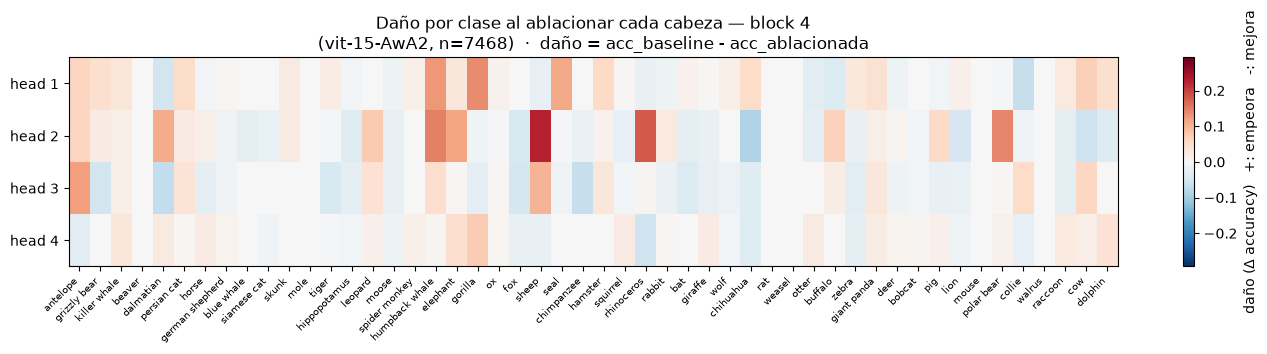

guardado: experimentation/experiments/30082026_head_specialization/damage_by_class_heatmap_vit-15-constrained-AwA2_block4.png


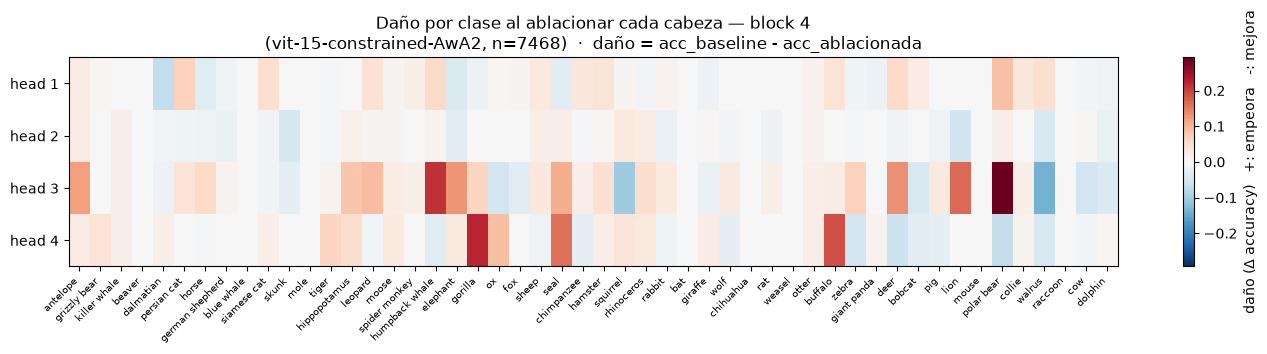

guardado: experimentation/experiments/30082026_head_specialization/damage_by_class_heatmap_vit-15-constrained_rank-AwA2_block4.png


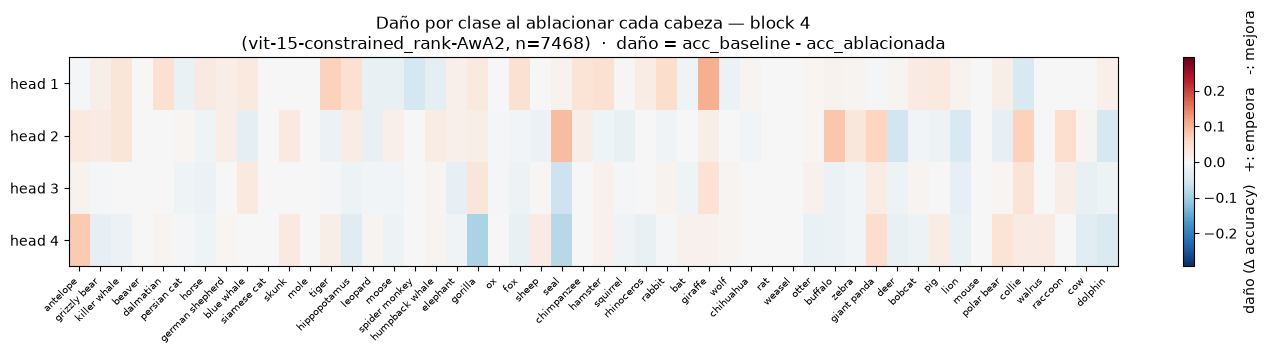

In [7]:
# --- Heatmap de la matriz de daño por clase (cabezas x clases) --------
# Escala divergente centrada en 0 (rojo = daña esa clase, azul = la mejora). COMPARTIDA
# entre modelos: 30% arriba del máximo |daño| del baseline (sin penalización), para que
# el mismo color sea comparable entre las dos figuras.
vmax_dmg = float(np.nanmax(np.abs(damage_matrix["unconstrained"]))) * 1.3
vmax_dmg = vmax_dmg if vmax_dmg > 0 else 1e-6

for key in MODELS:
    fig, ax = plt.subplots(figsize=(14, 3.6))
    im = ax.imshow(damage_matrix[key], cmap="RdBu_r", vmin=-vmax_dmg, vmax=vmax_dmg, aspect="auto")
    ax.set_xticks(range(num_classes)); ax.set_xticklabels(classes, rotation=45, ha="right", fontsize=7)
    ax.set_yticks(range(n_heads)); ax.set_yticklabels(head_labels)
    ax.set_title(f"Daño por clase al ablacionar cada cabeza — block {BLOCK_IDX}\n"
                 f"({MODELS[key]}, n={N_REF})  ·  daño = acc_baseline - acc_ablacionada")
    fig.colorbar(im, ax=ax, label="daño (Δ accuracy)   +: empeora   -: mejora")
    plt.tight_layout()
    save_fig(fig, "damage_by_class_heatmap", OUTPUT_DIR, tag=f"{MODELS[key]}_block{BLOCK_IDX}", project_root=project_root)
    plt.show()

## Tarea 3 — Similitud pareada entre vectores de daño

Con `damage_matrix` (4×10), para los 6 pares `(1,2) (1,3) (1,4) (2,3) (2,4) (3,4)`:

- **Coseno**: `<d_i, d_j> / (||d_i|| ||d_j||)`. Sensible tanto a la *dirección* (qué clases) como al
  hecho de que ambos vectores apunten "hacia daño positivo".
- **Pearson** (control): coseno **después de centrar** cada vector (restarle su media). Al quitar la
  media, controla por el caso "esta cabeza daña más en general a todas las clases por igual" y deja
  solo el patrón *relativo* entre clases — si Pearson es bajo pero coseno alto, el parecido venía sobre
  todo de la magnitud media, no de atacar las mismas clases.

Se arman dos matrices `4×4` simétricas (diagonal = 1) y se reporta el **promedio de las 6 similitudes
fuera de la diagonal** para cada métrica: un escalar de coseno y un escalar de Pearson por corrida.

In [8]:
from modules.similarity import offdiag_mean, pairwise_similarity_matrix


cosine_matrix, pearson_matrix = {}, {}
promedio_similitud_coseno, promedio_similitud_pearson = {}, {}

for key in MODELS:
    cosine_matrix[key]  = pairwise_similarity_matrix(damage_matrix[key], "cosine")
    pearson_matrix[key] = pairwise_similarity_matrix(damage_matrix[key], "pearson")

    promedio_similitud_coseno[key]  = offdiag_mean(cosine_matrix[key])
    promedio_similitud_pearson[key] = offdiag_mean(pearson_matrix[key])

    print(f"[{key}] Matriz de similitud COSENO (vectores de daño):")
    print(pd.DataFrame(cosine_matrix[key], index=head_labels, columns=head_labels).round(3))
    print(f"[{key}] Matriz de similitud PEARSON (vectores de daño):")
    print(pd.DataFrame(pearson_matrix[key], index=head_labels, columns=head_labels).round(3))
    print(f"[{key}] promedio_similitud_coseno  (6 pares) = {promedio_similitud_coseno[key]:.4f}")
    print(f"[{key}] promedio_similitud_pearson (6 pares) = {promedio_similitud_pearson[key]:.4f}\n")

[unconstrained] Matriz de similitud COSENO (vectores de daño):
        head 1  head 2  head 3  head 4
head 1   1.000  -0.014   0.114   0.328
head 2  -0.014   1.000   0.387  -0.035
head 3   0.114   0.387   1.000  -0.157
head 4   0.328  -0.035  -0.157   1.000
[unconstrained] Matriz de similitud PEARSON (vectores de daño):
        head 1  head 2  head 3  head 4
head 1   1.000  -0.111   0.143   0.278
head 2  -0.111   1.000   0.412  -0.089
head 3   0.143   0.412   1.000  -0.150
head 4   0.278  -0.089  -0.150   1.000
[unconstrained] promedio_similitud_coseno  (6 pares) = 0.1038
[unconstrained] promedio_similitud_pearson (6 pares) = 0.0805

[constrained] Matriz de similitud COSENO (vectores de daño):
        head 1  head 2  head 3  head 4
head 1   1.000   0.071   0.342  -0.196
head 2   0.071   1.000   0.036   0.160
head 3   0.342   0.036   1.000   0.028
head 4  -0.196   0.160   0.028   1.000
[constrained] Matriz de similitud PEARSON (vectores de daño):
        head 1  head 2  head 3  head 4
h

guardado: experimentation/experiments/30082026_head_specialization/cosine_similarity_heatmap_vit-15-AwA2_block4.png


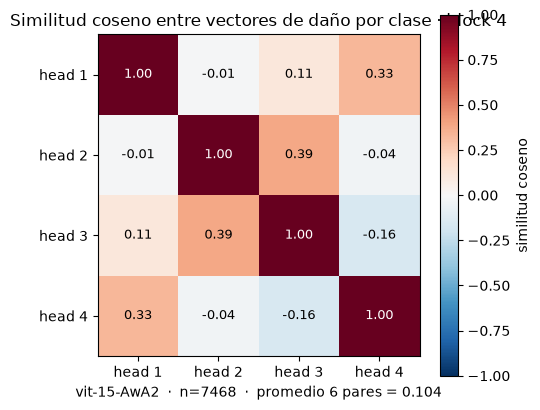

guardado: experimentation/experiments/30082026_head_specialization/pearson_similarity_heatmap_vit-15-AwA2_block4.png


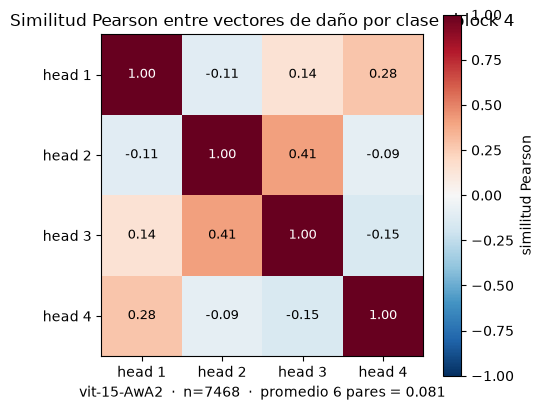

guardado: experimentation/experiments/30082026_head_specialization/cosine_similarity_heatmap_vit-15-constrained-AwA2_block4.png


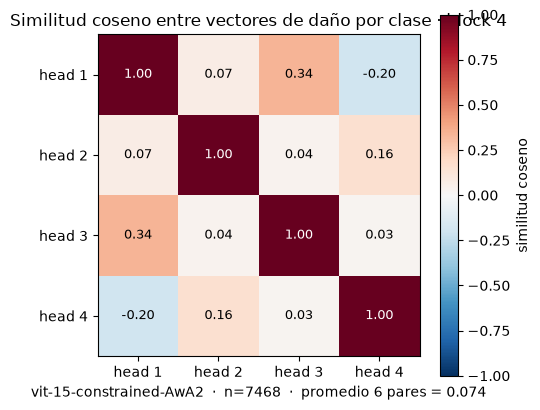

guardado: experimentation/experiments/30082026_head_specialization/pearson_similarity_heatmap_vit-15-constrained-AwA2_block4.png


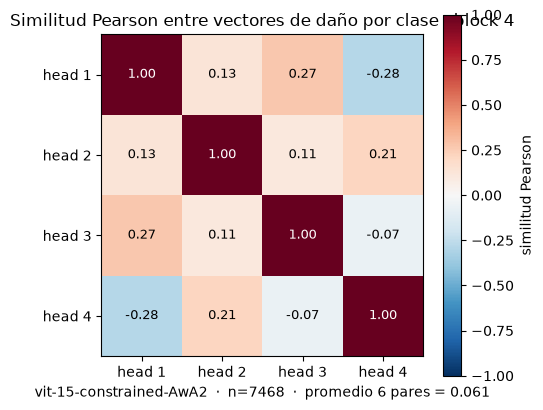

guardado: experimentation/experiments/30082026_head_specialization/cosine_similarity_heatmap_vit-15-constrained_rank-AwA2_block4.png


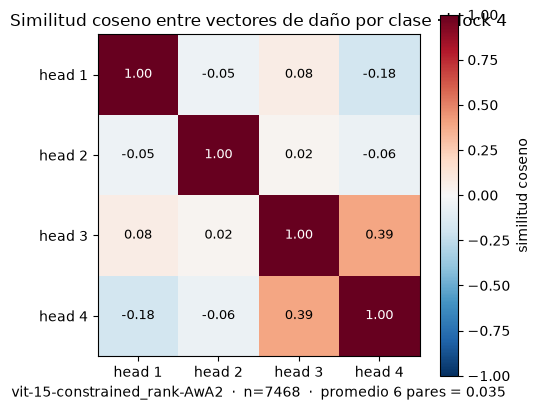

guardado: experimentation/experiments/30082026_head_specialization/pearson_similarity_heatmap_vit-15-constrained_rank-AwA2_block4.png


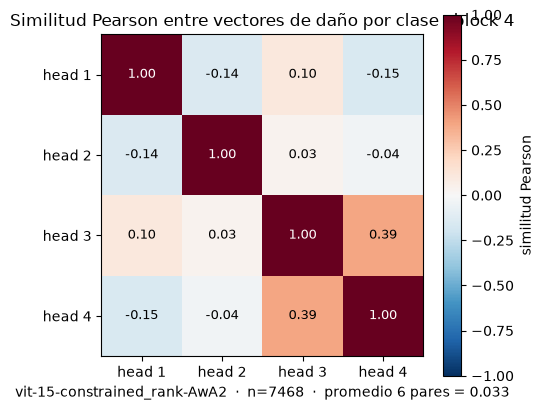

In [9]:
# --- Heatmaps de las dos matrices de similitud (4x4), un modelo por vez -----------------
# Escala fija [-1, 1] para comparar entre corridas.
for key in MODELS:
    for M, name, stem in [
        (cosine_matrix[key],  "coseno",  "cosine_similarity_heatmap"),
        (pearson_matrix[key], "Pearson", "pearson_similarity_heatmap"),
    ]:
        fig, ax = plt.subplots(figsize=(5.2, 4.4))
        im = ax.imshow(M, cmap="RdBu_r", vmin=-1.0, vmax=1.0)
        ax.set_xticks(range(n_heads)); ax.set_xticklabels(head_labels)
        ax.set_yticks(range(n_heads)); ax.set_yticklabels(head_labels)
        for i in range(n_heads):
            for j in range(n_heads):
                v = M[i, j]
                ax.text(j, i, "n/a" if np.isnan(v) else f"{v:.2f}", ha="center", va="center",
                        fontsize=9, color="white" if abs(np.nan_to_num(v)) > 0.6 else "black")
        mean_val = promedio_similitud_coseno[key] if name == "coseno" else promedio_similitud_pearson[key]
        ax.set_title(f"Similitud {name} entre vectores de daño por clase · block {BLOCK_IDX}")
        ax.set_xlabel(f"{MODELS[key]}  ·  n={N_REF}  ·  promedio 6 pares = {mean_val:.3f}")
        fig.colorbar(im, ax=ax, label=f"similitud {name}")
        plt.tight_layout()
        save_fig(fig, stem, OUTPUT_DIR, tag=f"{MODELS[key]}_block{BLOCK_IDX}", project_root=project_root)
        plt.show()

## Tabla resumen (CSV)

Un único CSV con todo lo del experimento: `accuracy_baseline_per_class` (10), `damage_vector` por
cabeza (4×10), matriz coseno (4×4), matriz Pearson (4×4) y los dos escalares resumen. Cada fila lleva
su etiqueta; las columnas de clase se usan para los vectores por clase, las de cabeza para las matrices
4×4, y la columna `scalar` para los dos promedios.

In [10]:
rows_all = []
for key in MODELS:
    rows = {}
    rows["accuracy_baseline_per_class"] = {name: accuracy_baseline_per_class[key][c] for c, name in enumerate(classes)}
    for h in range(n_heads):
        rows[f"damage_vector__{head_labels[h]}"] = {name: damage_matrix[key][h, c] for c, name in enumerate(classes)}
    for h in range(n_heads):
        rows[f"cosine_similarity__{head_labels[h]}"] = {head_labels[j]: cosine_matrix[key][h, j] for j in range(n_heads)}
    for h in range(n_heads):
        rows[f"pearson_similarity__{head_labels[h]}"] = {head_labels[j]: pearson_matrix[key][h, j] for j in range(n_heads)}
    rows["promedio_similitud_coseno"]  = {"scalar": promedio_similitud_coseno[key]}
    rows["promedio_similitud_pearson"] = {"scalar": promedio_similitud_pearson[key]}

    df = pd.DataFrame.from_dict(rows, orient="index")
    df = df.reindex(columns=classes + head_labels + ["scalar"])
    df.index.name = "row"
    df.insert(0, "model_name", MODELS[key])
    df.insert(1, "variant", key)
    df.insert(2, "block_idx", BLOCK_IDX)
    rows_all.append(df)

summary_df = pd.concat(rows_all)
csv_path = OUTPUT_DIR / f"head_specialization_block{BLOCK_IDX}.csv"
summary_df.to_csv(csv_path)
print(f"guardado: {csv_path.relative_to(project_root)}")
summary_df

guardado: experimentation/experiments/30082026_head_specialization/head_specialization_block4.csv


,model_name,variant,block_idx,antelope,grizzly bear,killer whale,beaver,dalmatian,persian cat,horse,...,collie,walrus,raccoon,cow,dolphin,head 1,head 2,head 3,head 4,scalar
row,,,,,,,,,,,,,,,,,,,,,
accuracy_baseline_per_class,vit-15-AwA2,unconstrained,4,0.344498,0.217647,0.034483,0.0,0.263636,0.167785,0.452888,...,0.339806,0.000000,0.156863,0.522388,0.746032,NaN,NaN,NaN,NaN,NaN
damage_vector__head 1,vit-15-AwA2,unconstrained,4,0.062201,0.047059,0.034483,0.0,-0.054545,0.053691,-0.009119,...,-0.067961,0.000000,0.029412,0.070895,0.047619,NaN,NaN,NaN,NaN,NaN
damage_vector__head 2,vit-15-AwA2,unconstrained,4,0.062201,0.023529,0.017241,0.0,0.109091,0.026846,0.018237,...,-0.009709,0.000000,-0.029412,-0.059702,-0.037037,NaN,NaN,NaN,NaN,NaN
damage_vector__head 3,vit-15-AwA2,unconstrained,4,0.119617,-0.052941,0.017241,0.0,-0.072727,0.040268,-0.027356,...,0.053398,0.000000,-0.029412,0.059701,0.000000,NaN,NaN,NaN,NaN,NaN
damage_vector__head 4,vit-15-AwA2,unconstrained,4,-0.033493,0.000000,0.034483,0.0,0.027273,0.006711,0.024316,...,-0.024272,0.000000,0.029412,0.018657,0.042328,NaN,NaN,NaN,NaN,NaN
cosine_similarity__head 1,vit-15-AwA2,unconstrained,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,1.000000,-0.013861,0.114282,0.328418,NaN
cosine_similarity__head 2,vit-15-AwA2,unconstrained,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,-0.013861,1.000000,0.386879,-0.035323,NaN
cosine_similarity__head 3,vit-15-AwA2,unconstrained,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0.114282,0.386879,1.000000,-0.157349,NaN
cosine_similarity__head 4,vit-15-AwA2,unconstrained,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0.328418,-0.035323,-0.157349,1.000000,NaN


## Resultado principal

In [11]:
line = "=" * 68
print(line)
print(f"  RESULTADO PRINCIPAL  ·  block {BLOCK_IDX}  ·  n={N_REF}")
print(line)
for key in MODELS:
    print(f"  {key:>13} ({MODELS[key]})")
    print(f"      promedio_similitud_coseno   (6 pares de cabezas) = {promedio_similitud_coseno[key]:+.4f}")
    print(f"      promedio_similitud_pearson  (6 pares de cabezas) = {promedio_similitud_pearson[key]:+.4f}")
print(line)
print("  Más bajo = cabezas MÁS especializadas (vectores de daño por clase menos")
print("  parecidos entre sí).")
print(line)

  RESULTADO PRINCIPAL  ·  block 4  ·  n=7468
  unconstrained (vit-15-AwA2)
      promedio_similitud_coseno   (6 pares de cabezas) = +0.1038
      promedio_similitud_pearson  (6 pares de cabezas) = +0.0805
    constrained (vit-15-constrained-AwA2)
      promedio_similitud_coseno   (6 pares de cabezas) = +0.0735
      promedio_similitud_pearson  (6 pares de cabezas) = +0.0613
  constrained_rank (vit-15-constrained_rank-AwA2)
      promedio_similitud_coseno   (6 pares de cabezas) = +0.0345
      promedio_similitud_pearson  (6 pares de cabezas) = +0.0326
  Más bajo = cabezas MÁS especializadas (vectores de daño por clase menos
  parecidos entre sí).


## Para reflexionar / siguientes pasos

- Correr con `MODEL_NAME = "vit-with-15-epochs"` y con `"vit-with-15-epochs-interpretable"`, para el
  mismo `BLOCK_IDX`, y comparar `promedio_similitud_coseno` / `promedio_similitud_pearson`. La hipótesis
  del capítulo (B) es que el modelo penalizado los tiene **más bajos** (cabezas menos redundantes).
- Repetir barriendo `BLOCK_IDX` sobre los 4 bloques: ¿la especialización aparece sobre todo en los
  bloques finales (los que ya "deciden" la clase, cf. logit lens) o está repartida?
- El heatmap de daño por clase permite leer *qué* clases concentra cada cabeza: si en el modelo
  interpretable cada cabeza tiene su propio conjunto de clases "rojas" y en el baseline varias cabezas
  comparten las mismas, eso es evidencia cualitativa directa de especialización.
- Complemento natural (mismo sample): repetir con 2-3 semillas (**C.6**, *universality*) sobre estos
  dos escalares resumen.